In [ ]:

# Load the fine-tuned model and class labels


MODEL_PATH = "/kaggle/input/models/muskaannarula/efficientnetb0-fine-tuned/tensorflow2/default/1/efficientnetb0_finetuned_best.keras"
CLASS_NAMES_PATH = "/kaggle/input/datasets/muskaannarula/class-names/efficientnetb0_class_names.json"

model = keras.models.load_model(MODEL_PATH)


with open(CLASS_NAMES_PATH, "r") as file:
    class_names = json.load(file)

base_model = model.get_layer("efficientnetb0")

print("Model:", model.name)
print("Number of classes:", len(class_names))

I0000 00:00:1784129021.608208      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1784129021.614046      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: plant_disease_efficientnetb0_frozen
Number of classes: 38


In [4]:
import json
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

In [ ]:

# Grad-CAM heatmap


def make_gradcam_heatmap(image_batch, model, base_model):
    """
    Creates a Grad-CAM heatmap for the model's predicted class.
    EfficientNet-B0 handles its own input rescaling internally,
    so image pixels remain in the original 0-255 range.
    """

    with tf.GradientTape() as tape:

        # Last convolutional feature maps from EfficientNet-B0
        conv_features = base_model(image_batch, training=False)

        # Pass these feature maps through your classifier head
        x = model.get_layer("global_average_pooling")(conv_features)
        x = model.get_layer("classifier_batch_norm")(x, training=False)
        x = model.get_layer("dense_256")(x)
        x = model.get_layer("dropout")(x, training=False)
        predictions = model.get_layer("disease_prediction")(x)

        # Explain the model's top prediction
        predicted_index = tf.argmax(predictions[0])
        predicted_score = predictions[:, predicted_index]

    # Compute how important each feature map is for the prediction
    gradients = tape.gradient(predicted_score, conv_features)

    # Average importance of each channel
    channel_weights = tf.reduce_mean(gradients, axis=(0, 1, 2))

    # Create weighted combination of feature maps
    conv_features = conv_features[0]
    heatmap = tf.reduce_sum(conv_features * channel_weights, axis=-1)

    # Keep positive values and normalize from 0 to 1
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + keras.backend.epsilon())

    predicted_index = int(predicted_index.numpy())
    confidence = float(predictions[0, predicted_index].numpy())

    return heatmap.numpy(), predicted_index, confidence

In [11]:
from pathlib import Path

TEST_DIR = "/kaggle/input/YOUR_DATASET"

for p in Path(TEST_DIR).rglob("*"):
    print(p)
    break

In [12]:
from pathlib import Path
import random

TEST_DIR = "/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/test/test"

image_paths = sorted(Path(TEST_DIR).glob("*.JPG"))

print("Total test images:", len(image_paths))

random.seed(42)
selected_images = random.sample(image_paths, 30)

Total test images: 33


In [13]:
import re

def get_true_label(filename):
    name = Path(filename).stem          # AppleScab3
    name = re.sub(r"\d+$", "", name)    # AppleScab
    return name

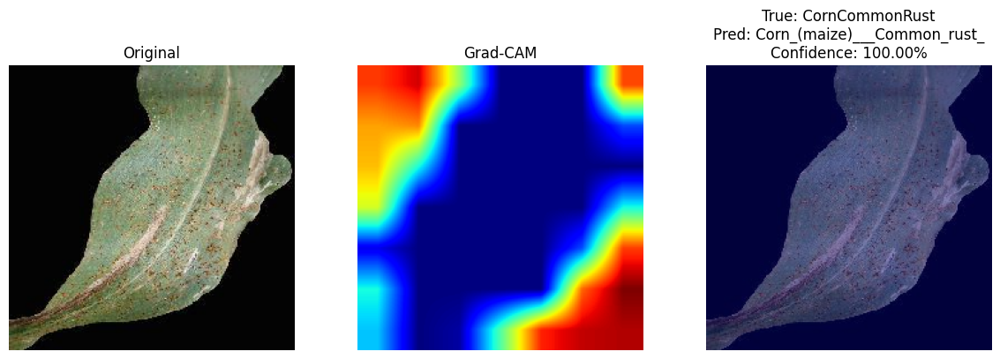

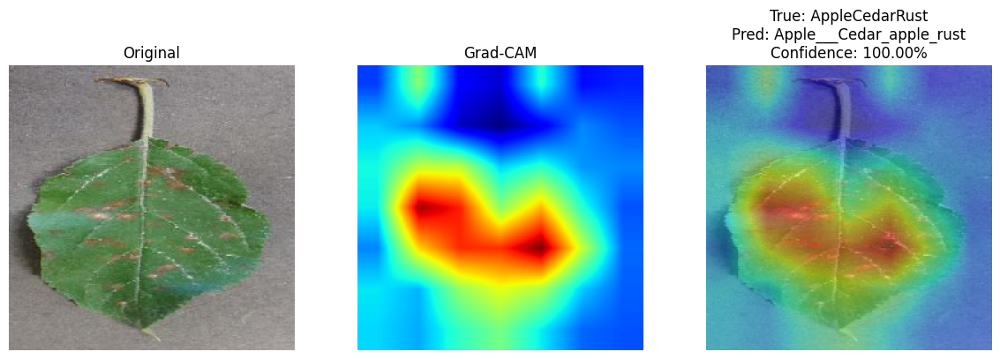

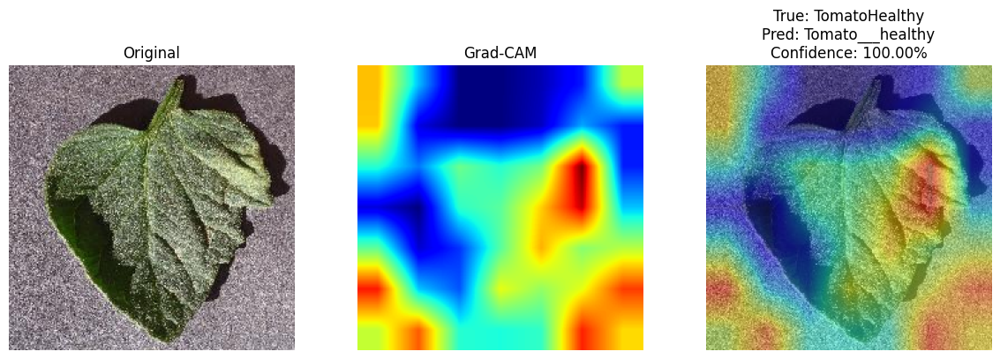

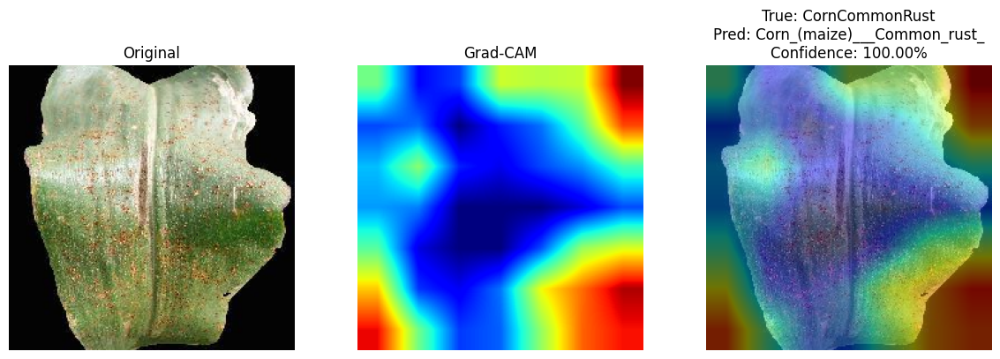

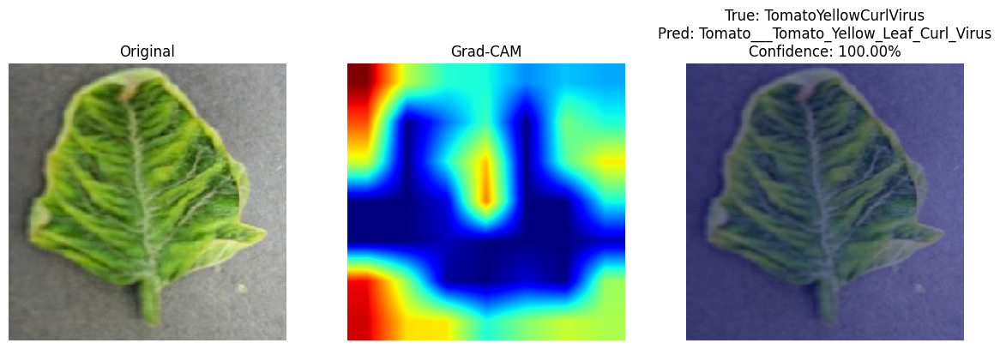

...

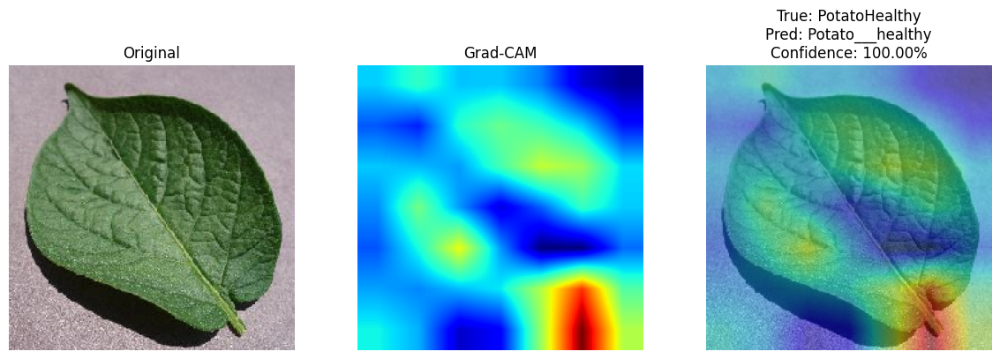

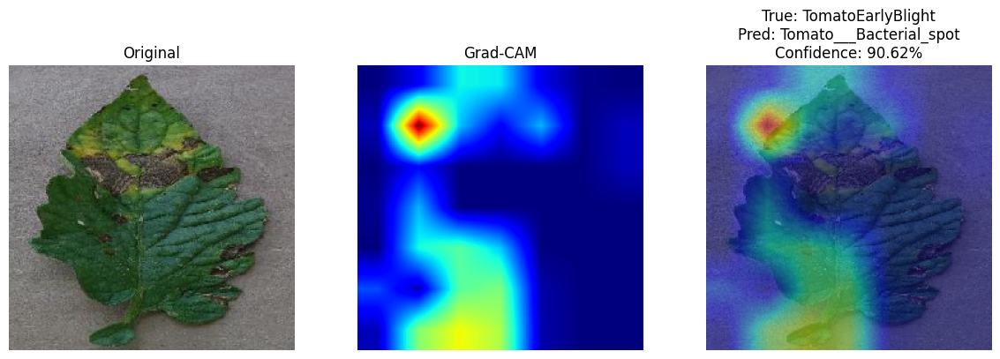

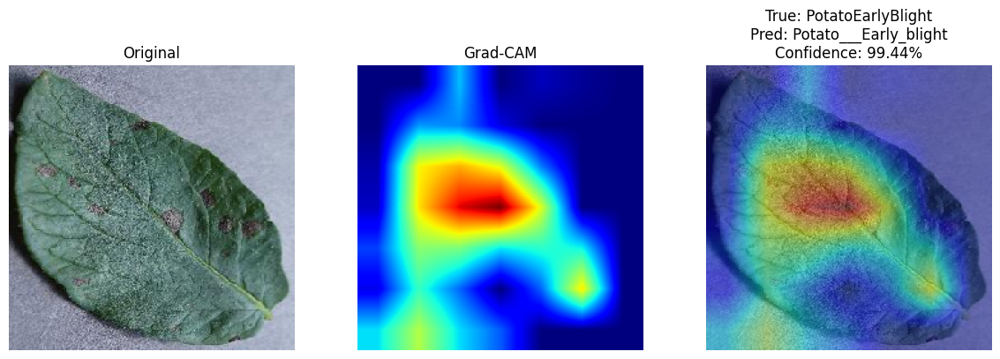

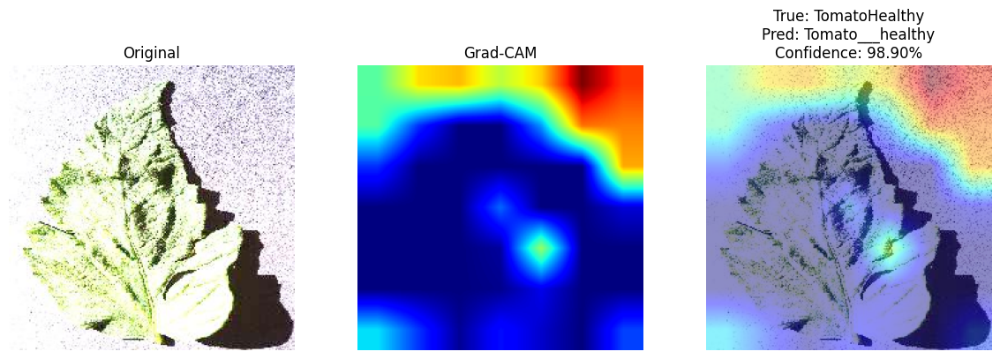

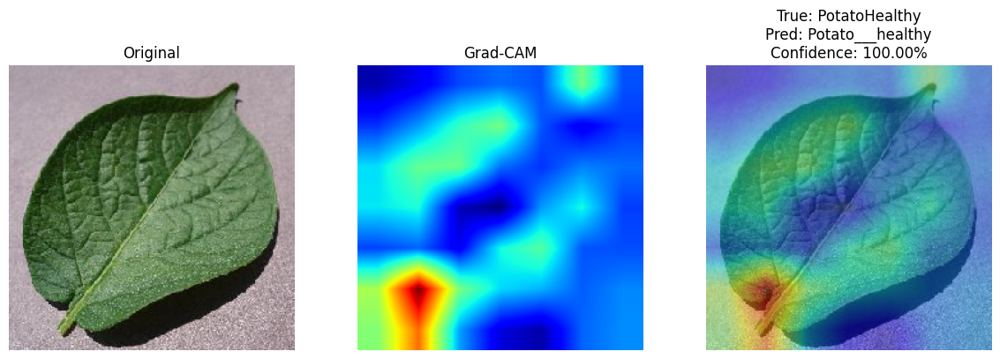

In [14]:
IMG_SIZE = 224

for img_path in selected_images:

    image = keras.utils.load_img(
        img_path,
        target_size=(IMG_SIZE, IMG_SIZE)
    )

    image_array = keras.utils.img_to_array(image)
    image_batch = np.expand_dims(image_array, axis=0)

    heatmap, predicted_index, confidence = make_gradcam_heatmap(
        image_batch,
        model,
        base_model
    )

    predicted_class = class_names[predicted_index]
    true_class = get_true_label(img_path.name)

    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis],
        (IMG_SIZE, IMG_SIZE)
    ).numpy().squeeze()

    heatmap_color = plt.colormaps["jet"](heatmap_resized)[..., :3]

    overlay = 0.55 * (image_array/255.0) + 0.45 * heatmap_color
    overlay = np.clip(overlay, 0, 1)

    plt.figure(figsize=(12,4))

    plt.subplot(1,3,1)
    plt.imshow(image)
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1,3,2)
    plt.imshow(heatmap_resized, cmap="jet")
    plt.title("Grad-CAM")
    plt.axis("off")

    plt.subplot(1,3,3)
    plt.imshow(overlay)
    plt.title(
        f"True: {true_class}\n"
        f"Pred: {predicted_class}\n"
        f"Confidence: {confidence:.2%}"
    )
    plt.axis("off")

    plt.tight_layout()
    plt.show()